# V2 第二部分　路徑比較，兩條各自接在最佳止點

⭐ 計畫在 Obsidian `15 Simulation subjects/V2/00 V2 PLAN — 先選止點，再比路徑.md` §4。 / 第一部分的結果在 `V2 P1 止點掃描 — 結果.md`。

## 0. 📖 故事：為什麼要做這一本

1. 第一部分找到了兩條路徑背屈（dorsiflexion）最強的止點
    - IO 在中間楔往外側楔四分之三（位置 2.75）
    - CT 在內側楔狀骨（位置 1.00）
2. 這一本回答 Karan 真正關心的事
    - 兩條都接在最好的地方時，誰把後足推向旋後（supination），誰推向旋前（pronation）
    - 推多強，分成繞距下軸的旋後／旋前，和力矩前後分量的內翻（inversion）／外翻（eversion）
    - 深腓神經麻痺（deep peroneal palsy）和腓總神經麻痺（common peroneal palsy）時，後足的淨力矩往哪邊
3. 比兩種組合
    - **A，主要**　IO 接 IO 的最佳點，CT 接 CT 的最佳點
    - **B，對照**　兩條接同一點，第一部分兩條平均最大的那一點
4. 開始前先做一個檢查，P3（支持帶那一點）左右各移 10 mm，最佳點會不會換人

## 1. 設定

### 📖 1.1. 載入引擎，從第一部分的 CSV 讀出最佳點

1. 最佳點不手打，直接從 `V2_part1_attachment_sweep.csv` 用同一個規則挑，第一部分改了這裡就跟著改
2. 規則是位置 1 到 5 裡面，14° 背屈力臂最大的那一點
3. B 組合是兩條 14° 力臂平均最大的那一點
4. 步態底色用第一版的 `gait_cycle.json`，已經複製到 `V2\data\`

In [ ]:
import csv  # 讀寫 CSV
import json  # 讀步態資料
import os  # 組路徑
import re  # 改 .osim 裡的文字
import sys  # 讓 python 找得到 V2 的引擎
import textwrap  # 圖上的長名字換行

import matplotlib.pyplot as plt  # 畫圖
import numpy as np  # 陣列
import opensim as osim  # OpenSim API
from tqdm import tqdm  # 進度條

ROOT = r"D:\OpenSim 4.6\Tendon transfer model\V2"  # V2 的程式資料夾
MODEL = os.path.join(ROOT, 'model', 'gait2392_simbody_original.osim')  # 原始 Gait2392
FIGURES = os.path.join(ROOT, 'figures')  # 圖存這裡，之後複製到 Obsidian
MODELS_DIR = os.path.join(ROOT, 'models', 'part2')  # 第二部分的 .osim 存這裡
sys.path.insert(0, ROOT)  # 先找 V2 自己的引擎
from transfer_engine import (  # noqa: E402
    PALSY_LEVELS, TransferEngine, lower_z_default, via_y_from_height,
)

ROUTES = {'IO': -0.020, 'CT': 0.028}  # 開窗中段點的內外側座標 z，公尺
VIA_Y = via_y_from_height(7.5)  # 開窗高度，內踝尖上方 7.5 cm
ANGLES = list(range(-20, 21))  # 曲線用的踝角度，每 1°
REPORT = [0, 14]  # 報數字的兩個角度

# 第一部分的結果
with open(os.path.join(ROOT, 'V2_part1_attachment_sweep.csv'), encoding='utf-8') as handle:
    part1 = [{key: (value if key in ('route', 'insertion') else float(value))
              for key, value in row.items()} for row in csv.DictReader(handle)]


def best_position(route):
    """位置 1 到 5 裡面，14° 背屈力臂最大的那一點。"""
    mine = [row for row in part1 if row['route'] == route and row['position'] >= 1]
    return max(mine, key=lambda row: row['dorsi_arm_14deg_mm'])['position']


positions = sorted({row['position'] for row in part1 if row['position'] >= 1})
common = max(positions, key=lambda p: np.mean(
    [row['dorsi_arm_14deg_mm'] for row in part1 if row['position'] == p]))


def xyz_at(route, position):
    """第一部分 CSV 裡某個位置的止點座標，公尺。"""
    row = next(r for r in part1 if r['route'] == route and r['position'] == position)
    return (row['x_mm'] / 1000, row['y_mm'] / 1000, row['z_mm'] / 1000), row['insertion']


CONFIGS = {  # 名字 → (路徑, 位置)
    'A_IO': ('IO', best_position('IO')),
    'A_CT': ('CT', best_position('CT')),
    'B_IO': ('IO', common),
    'B_CT': ('CT', common),
}
STYLE = {  # 顏色、線寬、線型，A 深色粗線，B 淺色細線
    'A_IO': ('#1f77b4', 2.6, '-'), 'A_CT': ('#ff7f0e', 2.6, '-'),
    'B_IO': ('#9ecae1', 1.8, '--'), 'B_CT': ('#fdd0a2', 1.8, '--'),
}
for name, (route, position) in CONFIGS.items():
    _, label = xyz_at(route, position)
    print(f'{name}: {route} at position {position:.2f} ({label})')
same = [name for name in ('B_IO', 'B_CT')
        if CONFIGS[name] == CONFIGS['A_' + name[2:]]]
print('B configurations identical to A:', same or 'none')

# 步態：站立期和擺盪期會用到的踝角度範圍
gait = json.load(open(os.path.join(ROOT, 'data', 'gait_cycle.json'), encoding='utf-8'))
ankle = np.array(gait['ankle_deg'])
stance = np.array(gait['percent']) <= gait['toe_off_pct']  # 離地之前是站立期
STANCE_RANGE = (ankle[stance].min(), ankle[stance].max())
SWING_RANGE = (ankle[~stance].min(), ankle[~stance].max())
print(f'stance {STANCE_RANGE[0]:+.1f} to {STANCE_RANGE[1]:+.1f} deg, '
      f'swing {SWING_RANGE[0]:+.1f} to {SWING_RANGE[1]:+.1f} deg')

engine = TransferEngine(MODEL)  # 載入一次，之後反覆改路徑

A_IO: IO at position 2.75 (intermediate_cuneiform_to_lateral_cuneiform)
A_CT: CT at position 1.00 (medial_cuneiform)
B_IO: IO at position 1.00 (medial_cuneiform)
B_CT: CT at position 1.00 (medial_cuneiform)
B configurations identical to A: ['B_CT']
stance -4.1 to +14.3 deg, swing -9.6 to +1.4 deg


### 👀 1.1. 比哪幾個組合

| 組合 | 路徑 | 止點 |
|---|---|---|
| ⭐ A_IO | IO | 位置 2.75，中間楔往外側楔四分之三 |
| ⭐ A_CT | CT | 位置 1.00，內側楔狀骨 |
| B_IO | IO | 位置 1.00，內側楔狀骨 |
| B_CT | CT | 位置 1.00，內側楔狀骨，⚠️ **和 A_CT 一模一樣** |

1. B 組合的共同點是內側楔狀骨，剛好就是 CT 的最佳點，所以 B_CT 等於 A_CT，圖上只畫一次
2. 站立期會用到的踝角度 −4.1° 到 +14.3°，擺盪期 −9.6° 到 +1.4°，畫底色用

## 2. 驗證，先對帳第一版

### 📖 2.1. 重現第一版止點掃描 20° 的後足數字

1. 第一版 `2. Attachement/models/models_index.csv` 有內側楔、中間楔在 20° 的兩個數字
    - 轉位肌自己的後足力矩（`hindfoot_moment_20deg_Nm`），正值是旋後
    - 腓總麻痺時的淨後足力矩（`net_hindfoot_common_20deg_Nm`）
2. 同樣的止點、同樣的 P3、同樣的高度，這一本要算出一樣的數字，差要小於 0.01 Nm

In [ ]:
V1_A1 = {  # (路徑, 止點): (轉位肌後足力矩, 腓總麻痺淨力矩)，第一版 models_index.csv
    ('IO', 'medial_cuneiform'): (-10.04, 23.528),
    ('CT', 'medial_cuneiform'): (6.415, 39.983),
    ('IO', 'intermediate_cuneiform'): (-8.982, 24.586),
    ('CT', 'intermediate_cuneiform'): (15.253, 48.821),
}
for (route, key), (donor_v1, net_v1) in V1_A1.items():
    engine.set_route(ROUTES[route], VIA_Y, insertion=engine.insertions[key]['xyz'])
    row = engine.profile([20.0])[0]
    donor, net = row['moment_subtalar_nm'], row['net_subtalar_nm']['common']
    ok = abs(donor - donor_v1) < 0.01 and abs(net - net_v1) < 0.01
    print(f'{route} {key:24s} donor {donor:+7.3f} (V1 {donor_v1:+7.3f})  '
          f'net common {net:+7.3f} (V1 {net_v1:+7.3f})  {"OK" if ok else "CHECK"}')

IO medial_cuneiform         donor -10.040 (V1 -10.040)  net common +23.528 (V1 +23.528)  OK
CT medial_cuneiform         donor  +6.415 (V1  +6.415)  net common +39.983 (V1 +39.983)  OK
IO intermediate_cuneiform   donor  -8.982 (V1  -8.982)  net common +24.586 (V1 +24.586)  OK
CT intermediate_cuneiform   donor +15.253 (V1 +15.253)  net common +48.821 (V1 +48.821)  OK


### 👀 2.1. 對帳結果

1. ✅ 四組都和第一版一樣，到小數第三位
    - IO 內側楔　轉位肌 −10.040、腓總麻痺淨值 +23.528 Nm
    - CT 內側楔　+6.415、+39.983 Nm
2. 所以這一本的後足數字和第一版是同一套計算，差別只來自止點

## 3. P3 動了，最佳點會不會換人

### 📖 3.1. P3 左右各移 10 mm，重掃第一部分

1. P3 是肌腱經過踝前方支持帶的那一點，第一版發現它對後足力矩影響很大
2. 這一格把 P3 往外側移 10 mm、不動、往內側移 10 mm，每條路徑把第一部分的 33 個點重掃一次
3. 看兩件事
    - 14° 背屈力臂最大的點有沒有換
    - 最佳點的旋後力臂（supination moment arm）正負號有沒有翻

In [ ]:
SHIFTS_MM = [-10, 0, 10]  # 負的是往外側，左腳 +z 是內側
p3_rows = []
for route, via_z in ROUTES.items():
    for shift in SHIFTS_MM:
        lower_z = lower_z_default(via_z) + shift / 1000  # 第一版規則再加上移動量
        for position in tqdm(positions, desc=f'{route} P3 {shift:+d} mm', leave=False):
            xyz, _ = xyz_at(route, position)
            engine.set_route(via_z, VIA_Y, insertion=xyz, lower_z=lower_z)
            result = engine.sweep_ankle([14.0])[0]
            p3_rows.append({'route': route, 'shift_mm': shift, 'position': position,
                            'dorsi_arm_14deg_mm': result['arm_ankle_mm'],
                            'supination_arm_14deg_mm': result['arm_subtalar_mm']})

for route in ROUTES:
    for shift in SHIFTS_MM:
        mine = [r for r in p3_rows if r['route'] == route and r['shift_mm'] == shift]
        best = max(mine, key=lambda r: r['dorsi_arm_14deg_mm'])
        plateau = [r['position'] for r in mine
                   if best['dorsi_arm_14deg_mm'] - r['dorsi_arm_14deg_mm'] < 0.5]
        print(f"{route} P3 {shift:+3d} mm: best {best['position']:.2f} "
              f"({best['dorsi_arm_14deg_mm']:.2f} mm), plateau {min(plateau):.2f} to {max(plateau):.2f}, "
              f"supination arm there {best['supination_arm_14deg_mm']:+.2f} mm")

IO P3 -10 mm: best 3.00 (34.97 mm), plateau 2.95 to 3.00, supination arm there -19.64 mm
IO P3  +0 mm: best 2.75 (32.37 mm), plateau 2.55 to 3.00, supination arm there -7.10 mm
IO P3 +10 mm: best 1.25 (25.84 mm), plateau 1.00 to 1.50, supination arm there -0.31 mm
CT P3 -10 mm: best 2.50 (27.24 mm), plateau 2.30 to 2.80, supination arm there +2.34 mm
CT P3  +0 mm: best 1.00 (24.65 mm), plateau 1.00 to 1.25, supination arm there +7.33 mm
CT P3 +10 mm: best 1.00 (22.10 mm), plateau 1.00 to 1.00, supination arm there +19.26 mm


### 👀 3.1. ⛔ 最佳點會跟著 P3 走

| P3 | IO 最佳點 | IO 14° 背屈力臂 | IO 旋後力臂 | CT 最佳點 | CT 14° 背屈力臂 | CT 旋後力臂 |
|---|---|---|---|---|---|---|
| 往外 10 mm | 3.00 外側楔 | 34.97 | −19.64 | 2.50 中間楔和外側楔中間 | 27.24 | +2.34 |
| ⭐ 第一版 | 2.75 | 32.37 | −7.10 | 1.00 內側楔 | 24.65 | +7.33 |
| 往內 10 mm | 1.25 內側楔旁 | 25.84 | −0.31 | 1.00 內側楔 | 22.10 | +19.26 |

1. ⛔ **最佳止點不是固定的**，P3 往外，兩條的最佳點都往外跑，P3 往內，都往內跑
2. ⭐ 肌腱經過支持帶的那一點，決定了止點接在哪裡背屈最好，兩個點大致在同一條線上
3. ✅ **方向沒有翻**，三種 P3 下 IO 在最佳點都是旋前或接近零（−19.6 到 −0.3 mm），CT 都是旋後（+2.3 到 +19.3 mm）
4. ⚠️ 但**大小差很多**，所以旋後、旋前的數字一定要附上「P3 用第一版的規則」這個前提

### 📖 3.2. 畫出來

1. 左邊 IO、右邊 CT，三條線是三個 P3 位置
2. 實線是第一版的 P3，★ 是每條線的最高點

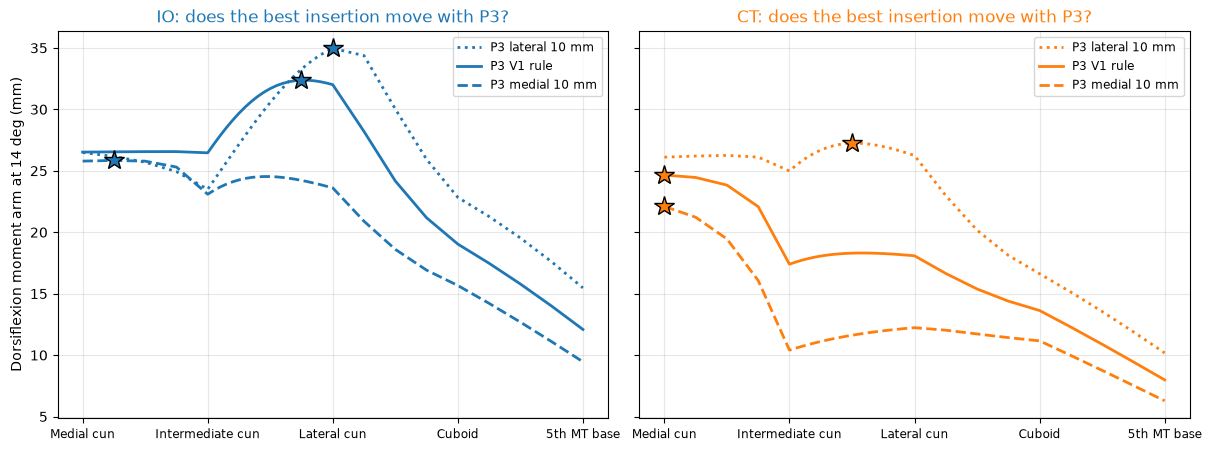

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True, constrained_layout=True)
shift_style = {-10: ('lateral 10 mm', ':'), 0: ('V1 rule', '-'), 10: ('medial 10 mm', '--')}
for axis, route in zip(axes, ROUTES):
    colour = STYLE['A_' + route][0]
    for shift, (label, line) in shift_style.items():
        mine = [r for r in p3_rows if r['route'] == route and r['shift_mm'] == shift]
        axis.plot([r['position'] for r in mine], [r['dorsi_arm_14deg_mm'] for r in mine],
                  line, color=colour, linewidth=2, label=f'P3 {label}')
        best = max(mine, key=lambda r: r['dorsi_arm_14deg_mm'])
        axis.plot(best['position'], best['dorsi_arm_14deg_mm'], '*', color=colour,
                  markersize=15, markeredgecolor='black')
    axis.set_xticks(range(1, 6))
    axis.set_xticklabels(['Medial cun', 'Intermediate cun', 'Lateral cun', 'Cuboid', '5th MT base'],
                         fontsize=8.5)
    axis.set_title(f'{route}: does the best insertion move with P3?', color=colour)
    axis.grid(alpha=0.3)
    axis.legend(fontsize=8.5)
axes[0].set_ylabel('Dorsiflexion moment arm at 14 deg (mm)')
plt.savefig(os.path.join(FIGURES, 'v2-p2-p3-sensitivity.png'), dpi=200, bbox_inches='tight')
plt.show()

### 👀 3.2. 怎麼讀這張圖

1. 實線是第一版的 P3，就是第一部分的結果
2. ⭐ **點線（P3 往外）** 兩條的 ★ 都往右移，IO 到外側楔、CT 到中間楔和外側楔之間
3. ⭐ **虛線（P3 往內）** IO 的 ★ 跑回內側楔旁邊，CT 留在內側楔
4. 所以要回答「接在哪裡最好」，先要知道肌腱在支持帶底下實際經過哪裡，這需要 Karan

## 4. 兩條路徑在最佳點上比方向

### 📖 4.1. 從 −20° 掃到 +20°

1. 每一個組合接好路徑，踝從 −20° 掃到 +20°，每 1° 一次
2. 每個角度記下旋後力臂、轉位肌的旋後力矩（活化度 1.0），和三種情況的淨後足力矩
    - 沒有麻痺
    - 深腓麻痺，脛前肌、伸趾長肌、伸拇長肌、第三腓骨肌沒了
    - 腓總麻痺，再加上兩條腓骨肌沒了
3. ⭐ 正值是旋後，負值是旋前

In [ ]:
curves = {}
for name in tqdm(CONFIGS, desc='configurations'):
    route, position = CONFIGS[name]
    xyz, _ = xyz_at(route, position)
    engine.set_route(ROUTES[route], VIA_Y, insertion=xyz)  # P3 用第一版的規則
    rows = engine.profile(ANGLES)  # 每個角度都算
    curves[name] = {
        'supination_arm_mm': np.array([r['arm_subtalar_mm'] for r in rows]),
        'supination_moment_Nm': np.array([r['moment_subtalar_nm'] for r in rows]),
        'dorsi_arm_mm': np.array([r['arm_ankle_mm'] for r in rows]),
        'force_N': np.array([r['force_n'] for r in rows]),  # 活化度 1.0 的肌腱力，§7 會用
        'net_Nm': {level: np.array([r['net_subtalar_nm'][level] for r in rows])
                   for level in PALSY_LEVELS},
    }
index = {angle: ANGLES.index(angle) for angle in REPORT}
for name, curve in curves.items():
    parts = [f"{angle:+3d} deg arm {curve['supination_arm_mm'][index[angle]]:+6.2f} mm, "
             f"moment {curve['supination_moment_Nm'][index[angle]]:+6.2f} Nm" for angle in REPORT]
    print(f'{name}: ' + ' | '.join(parts))

A_IO:  +0 deg arm  -8.73 mm, moment -11.56 Nm | +14 deg arm  -7.10 mm, moment  -6.65 Nm
A_CT:  +0 deg arm  +7.33 mm, moment  +9.43 Nm | +14 deg arm  +7.33 mm, moment  +7.14 Nm
B_IO:  +0 deg arm  -9.08 mm, moment -11.64 Nm | +14 deg arm -11.43 mm, moment -10.85 Nm
B_CT:  +0 deg arm  +7.33 mm, moment  +9.43 Nm | +14 deg arm  +7.33 mm, moment  +7.14 Nm


### 👀 4.1. 旋後力臂和力矩

| 組合 | 0° 力臂 mm | 14° 力臂 mm | 0° 力矩 Nm | 14° 力矩 Nm |
|---|---|---|---|---|
| ⭐ A_IO，IO 接 2.75 | −8.73 | −7.10 | −11.56 | −6.65 |
| ⭐ A_CT，CT 接內側楔 | +7.33 | +7.33 | +9.43 | +7.14 |
| B_IO，IO 接內側楔 | −9.08 | −11.43 | −11.64 | −10.85 |

1. ⭐ **A 組合，IO 推向旋前，CT 推向旋後**，兩條各自接在最好的地方也一樣
2. 和第一版都接中間楔比
    - CT 的 14° 旋後力臂從 +13.06 降到 **+7.33 mm**，接內側楔讓 CT 的旋後少了四成
    - IO 的 14° 旋前力臂從 −10.42 變成 **−7.10 mm**，接偏外側讓 IO 的旋前少了三成
3. B_IO 接內側楔，14° 旋前比 A_IO 多（−11.43 對 −7.10 mm），但背屈力臂少（26.52 對 32.37 mm），IO 在背屈和矯正之間有取捨

### 📖 4.2. 畫圖一：旋後力臂和旋後力矩對踝角度

1. 左圖力臂（mm），右圖力矩（Nm），零線以上旋後、以下旋前
2. A 組合是深色粗線，B 組合是淺色虛線
3. 綠底是站立期會用到的踝角度，藍灰底是擺盪期

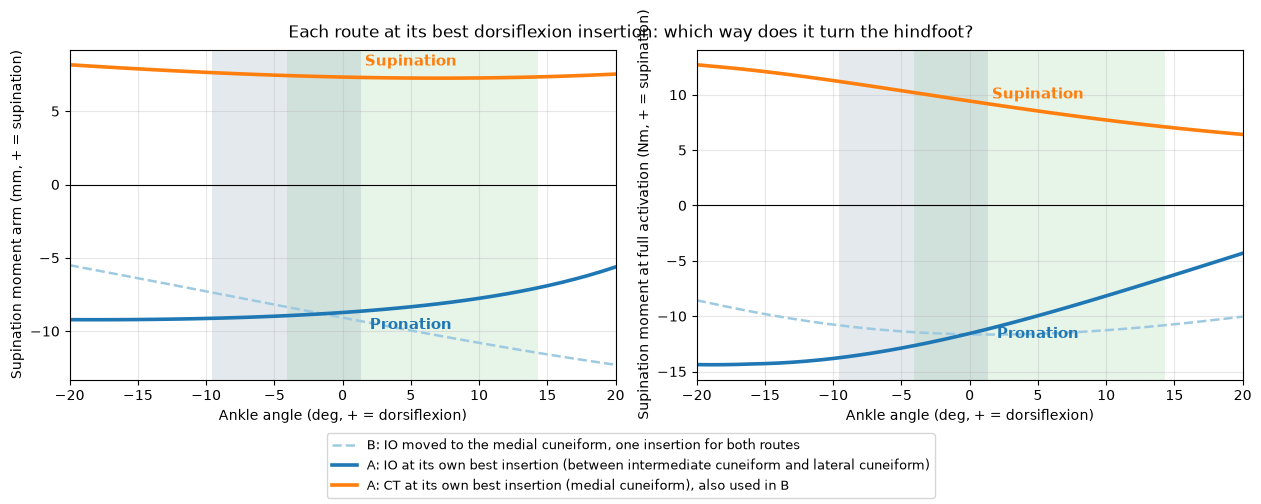

In [ ]:
def shade_gait(axis):
    """畫出站立期和擺盪期會用到的踝角度範圍。"""
    axis.axvspan(*STANCE_RANGE, color='#4CAF50', alpha=0.13, linewidth=0)
    axis.axvspan(*SWING_RANGE, color='#5C7C99', alpha=0.16, linewidth=0)


def readable(position):
    """位置換成看得懂的止點名稱，圖上用英文。"""
    names = ['navicular', 'medial cuneiform', 'intermediate cuneiform',
             'lateral cuneiform', 'cuboid', 'base of 5th metatarsal']
    if abs(position - round(position)) < 1e-9:
        return names[int(round(position))]
    low = int(position)
    return f'between {names[low]} and {names[low + 1]}'


# 圖例寫清楚每條線接在哪裡，不用「common point」這種看不懂的說法
LABELS = {
    'A_IO': f"A: IO at its own best insertion ({readable(CONFIGS['A_IO'][1])})",
    'A_CT': f"A: CT at its own best insertion ({readable(CONFIGS['A_CT'][1])})",
    'B_IO': f"B: IO moved to the {readable(CONFIGS['B_IO'][1])}, one insertion for both routes",
    'B_CT': f"B: CT at the {readable(CONFIGS['B_CT'][1])}, one insertion for both routes",
}
for name in same:  # B 和 A 同一點時，圖例寫清楚
    LABELS['A_' + name[2:]] += ', also used in B'
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), constrained_layout=True)
for axis, key, ylabel in ((axes[0], 'supination_arm_mm', 'Supination moment arm (mm, + = supination)'),
                          (axes[1], 'supination_moment_Nm', 'Supination moment at full activation (Nm, + = supination)')):
    shade_gait(axis)
    for name in ('B_IO', 'B_CT', 'A_IO', 'A_CT'):  # B 先畫，A 疊在上面
        if name in same:
            continue  # 和 A 一模一樣的就不重複畫
        colour, width, line = STYLE[name]
        axis.plot(ANGLES, curves[name][key], line, color=colour, linewidth=width,
                  label=LABELS[name])
    axis.axhline(0, color='black', linewidth=0.8)
    # 直接在線上寫方向
    at = ANGLES.index(5)
    for name, word, lift in (('A_IO', 'Pronation', -16), ('A_CT', 'Supination', 9)):
        axis.annotate(word, (5, curves[name][key][at]), xytext=(0, lift),
                      textcoords='offset points', ha='center', fontsize=11,
                      fontweight='bold', color=STYLE[name][0])
    axis.set_xlim(-20, 20)
    axis.set_xlabel('Ankle angle (deg, + = dorsiflexion)')
    axis.set_ylabel(ylabel)
    axis.grid(alpha=0.3)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=1, fontsize=9)  # 圖例放下面，不擋線
fig.suptitle('Each route at its best dorsiflexion insertion: which way does it turn the hindfoot?')
plt.savefig(os.path.join(FIGURES, 'v2-p2-supination-vs-ankle.png'), dpi=200, bbox_inches='tight')
plt.show()

### 👀 4.2. 怎麼讀圖一

1. ⭐ **橘色（CT）** 整條在零線以上，旋後，力臂在整個角度範圍幾乎是平的，約 +7.3 mm
2. ⭐ **深藍（A_IO）** 整條在零線以下，旋前，越背屈越接近零
3. **淺藍虛線（B_IO，IO 接內側楔）** 越背屈旋前越多，在 +1° 左右和深藍交叉
4. 右圖是力矩，形狀多了肌力的影響，越背屈肌肉越短、力越小，所以兩條都往零線靠
5. 在綠底和藍灰底的範圍裡，也就是走路真的會用到的角度，方向都沒有變

## 5. 中立位和 14° 的數字

### 📖 5.1. 把力拆成三個方向，加上麻痺時的淨值

1. 引擎的 `decompose()` 把兩個關節的力臂合成一個三維向量，再拆成背屈、內翻、內收三個分量
    - 內翻（inversion）正、外翻（eversion）負
    - 內收（adduction）正、外展（abduction）負
2. ⚠️ 距下關節只有一個軸，真正會轉的是旋後／旋前。 / 內翻／外翻是這個向量的一個分量，用來回答 Karan 的 "eversion or corrective power"
3. 淨後足力矩（net hindfoot moment）是轉位肌加上其他所有跨過距下關節、還有神經的肌肉，全部全力收縮
4. 結果存成 `V2_part2_routing_at_best.csv`

In [ ]:
table = []
for name, (route, position) in CONFIGS.items():
    xyz, label = xyz_at(route, position)
    engine.set_route(ROUTES[route], VIA_Y, insertion=xyz)
    for angle in REPORT:
        parts = engine.decompose(float(angle))  # 三個方向的分量
        at = index[angle]
        table.append({
            'config': name, 'route': route, 'position': position, 'insertion': label,
            'angle_deg': angle,
            'dorsi_arm_mm': curves[name]['dorsi_arm_mm'][at],
            'supination_arm_mm': curves[name]['supination_arm_mm'][at],
            'supination_moment_Nm': curves[name]['supination_moment_Nm'][at],
            'inversion_component_mm': parts['inversion_mm'],
            'adduction_component_mm': parts['adduction_mm'],
            'wasted_pct': parts['wasted_pct'],
            'net_none_Nm': curves[name]['net_Nm']['none'][at],
            'net_deep_palsy_Nm': curves[name]['net_Nm']['deep'][at],
            'net_common_palsy_Nm': curves[name]['net_Nm']['common'][at],
        })

with open(os.path.join(ROOT, 'V2_part2_routing_at_best.csv'), 'w', newline='', encoding='utf-8') as handle:
    writer = csv.DictWriter(handle, fieldnames=list(table[0]))
    writer.writeheader()
    writer.writerows([{k: (round(v, 4) if isinstance(v, float) else v) for k, v in row.items()}
                      for row in table])

header = f"{'config':6s} {'deg':>4s} {'sup arm':>8s} {'sup Nm':>7s} {'inv':>7s} {'add':>7s} {'deep':>7s} {'common':>7s}"
print(header)
for row in table:
    print(f"{row['config']:6s} {row['angle_deg']:4d} {row['supination_arm_mm']:+8.2f} "
          f"{row['supination_moment_Nm']:+7.2f} {row['inversion_component_mm']:+7.2f} "
          f"{row['adduction_component_mm']:+7.2f} {row['net_deep_palsy_Nm']:+7.2f} "
          f"{row['net_common_palsy_Nm']:+7.2f}")

config  deg  sup arm  sup Nm     inv     add    deep  common
A_IO      0    -8.73  -11.56  -10.41  -11.14  -18.44  +17.50
A_IO     14    -7.10   -6.65   -8.99   -9.93  -10.07  +26.69
A_CT      0    +7.33   +9.43   +2.71   -0.64   +2.55  +38.49
A_CT     14    +7.33   +7.14   +3.18   +0.14   +3.71  +40.48
B_IO      0    -9.08  -11.64  -10.35  -10.79  -18.52  +17.42
B_IO     14   -11.43  -10.85  -11.79  -11.53  -14.27  +22.49
B_CT      0    +7.33   +9.43   +2.71   -0.64   +2.55  +38.49
B_CT     14    +7.33   +7.14   +3.18   +0.14   +3.71  +40.48


### 👀 5.1. 中立位和 14° 的數字

1. **內翻／外翻分量**
    - A_IO −10.41 / −8.99 mm，外翻
    - A_CT +2.71 / +3.18 mm，一點點內翻
    - B_IO −10.35 / −11.79 mm，外翻
2. **內收／外展分量**　IO 兩個都是外展（約 −10 到 −11.5 mm），CT 接近零
3. ⭐ **深腓麻痺（腓骨肌還在）的淨後足力矩**
    - A_IO −18.44 / −10.07 Nm，淨值推向旋前，**有矯正**
    - A_CT +2.55 / +3.71 Nm，淨值一點點旋後，**沒有矯正**
    - B_IO −18.52 / −14.27 Nm
4. ⛔ **腓總麻痺（腓骨肌也沒了）的淨後足力矩**
    - A_IO +17.50 / +26.69 Nm
    - A_CT +38.49 / +40.48 Nm，大約是 IO 的 1.5 到 2.2 倍
    - B_IO +17.42 / +22.49 Nm
    - 全部是旋後，單一止點抵不過，和第一版的結論一樣

### 📖 5.2. 畫圖二：中立位和 14° 並排

1. 四張小圖　內翻／外翻分量、轉位肌的旋後力矩、深腓麻痺的淨後足力矩、腓總麻痺的淨後足力矩
2. 每一組是一個組合，實心是中立位，斜線是 14°
3. 零線以上是往畸形那一邊（內翻、旋後），以下是往矯正那一邊

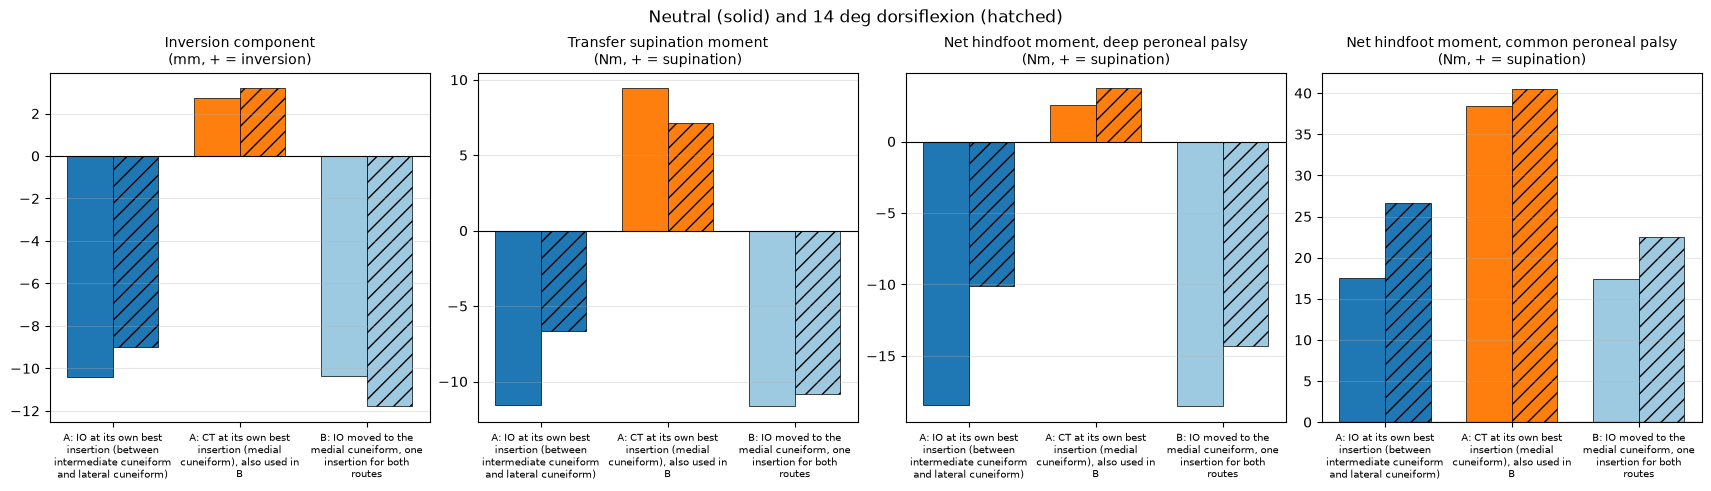

In [ ]:
shown = [name for name in CONFIGS if name not in same]  # 和 A 一樣的 B 不重複畫
fig, axes = plt.subplots(1, 4, figsize=(17, 4.8), constrained_layout=True)
panels = [('inversion_component_mm', 'Inversion component\n(mm, + = inversion)'),
          ('supination_moment_Nm', 'Transfer supination moment\n(Nm, + = supination)'),
          ('net_deep_palsy_Nm', 'Net hindfoot moment, deep peroneal palsy\n(Nm, + = supination)'),
          ('net_common_palsy_Nm', 'Net hindfoot moment, common peroneal palsy\n(Nm, + = supination)')]
width = 0.36
for axis, (key, title) in zip(axes, panels):
    for i, name in enumerate(shown):
        colour = STYLE[name][0]
        for j, angle in enumerate(REPORT):  # 實心中立位，斜線 14°
            row = next(r for r in table if r['config'] == name and r['angle_deg'] == angle)
            axis.bar(i + (j - 0.5) * width, row[key], width, color=colour,
                     hatch='//' if angle else '', edgecolor='black', linewidth=0.5)
    axis.axhline(0, color='black', linewidth=0.8)
    axis.set_xticks(range(len(shown)))
    axis.set_xticklabels([textwrap.fill(LABELS[n], 24) for n in shown], fontsize=7)  # 長名字自動換行
    axis.set_title(title, fontsize=10)
    axis.grid(axis='y', alpha=0.3)
fig.suptitle('Neutral (solid) and 14 deg dorsiflexion (hatched)')
plt.savefig(os.path.join(FIGURES, 'v2-p2-bars-neutral-14deg.png'), dpi=200, bbox_inches='tight')
plt.show()

### 👀 5.2. 怎麼讀圖二

1. 第一張，IO 的兩根都在零線以下（外翻），CT 在零線以上（內翻），但 CT 只有 3 mm 左右
2. 第二張，轉位肌自己的旋後力矩，IO 負、CT 正
3. ⭐ 第三張，深腓麻痺時 **IO 的淨值在零線以下，CT 在零線以上**，這是兩條路徑差別最清楚的一張
4. ⛔ 第四張，腓總麻痺時全部在零線以上，CT 最高

## 6. 存成 OpenSim GUI 打得開的模型

### 📖 6.1. 每個組合三個版本

1. 正常、深腓麻痺、腓總麻痺，麻痺的肌肉把最大等長力設成 1 N，和第一版 `build_transfer_models.py` 一樣，⛔ 不刪肌肉
2. 顏色照單一模型的規則，IO 藍、CT 橘
3. 和 A 一模一樣的 B 組合只存一次，檔名寫 `AB`
4. 存完重新載入，再算一次中立位和 14° 的旋後力臂、背屈力臂，還要確認麻痺的肌肉真的是 1 N

In [ ]:
os.makedirs(MODELS_DIR, exist_ok=True)
SINGLE_COLOUR = {'IO': '#1f77b4', 'CT': '#ff7f0e'}


def rgb(colour):
    colour = colour.lstrip('#')
    return osim.Vec3(*(int(colour[i:i + 2], 16) / 255 for i in (0, 2, 4)))


unique = {}  # (路徑, 位置) → 用到它的組合
for name, key in CONFIGS.items():
    unique.setdefault(key, []).append(name)

index_rows, worst = [], 0.0
jobs = [(key, names, level) for key, names in unique.items() for level in PALSY_LEVELS]
for (route, position), names, level in tqdm(jobs, desc='save and reload'):
    xyz, label = xyz_at(route, position)
    engine.set_route(ROUTES[route], VIA_Y, insertion=xyz)
    engine._pose(0.0, 0.0)  # 存檔前擺回中立位
    expected = engine.sweep_ankle(REPORT)
    engine.donor.getGeometryPath().upd_Appearance().set_color(rgb(SINGLE_COLOUR[route]))
    for muscle in PALSY_LEVELS[level]:  # 麻痺：力設成 1 N
        engine.muscles.get(muscle).setMaxIsometricForce(1.0)
    groups = ''.join(sorted({n[0] for n in names}))  # A、B 或 AB
    suffix = '' if level == 'none' else f'_{level}Palsy'
    stem = f'V2_P2_{groups}_{route}_pos{position:.2f}_{label}{suffix}'
    engine.model.setName(stem)
    path = os.path.join(MODELS_DIR, stem + '.osim')
    engine.model.printToXML(path)
    for muscle in PALSY_LEVELS[level]:  # 還原，下一個設定才不會被影響
        engine.muscles.get(muscle).setMaxIsometricForce(engine.original_force[muscle])

    fresh = TransferEngine(path)
    again = fresh.sweep_ankle(REPORT)
    gap = max(max(abs(again[i]['arm_subtalar_mm'] - expected[i]['arm_subtalar_mm']),
                  abs(again[i]['arm_ankle_mm'] - expected[i]['arm_ankle_mm'])) for i in range(2))
    palsy_ok = all(abs(fresh.original_force[m] - 1.0) < 1e-9 for m in PALSY_LEVELS[level])
    worst = max(worst, gap)
    index_rows.append({'file': stem + '.osim', 'configs': '+'.join(names).replace('+', ' and '),
                       'route': route, 'position': position, 'insertion': label, 'palsy': level,
                       'supination_arm_0deg_mm': round(expected[0]['arm_subtalar_mm'], 4),
                       'supination_arm_14deg_mm': round(expected[1]['arm_subtalar_mm'], 4),
                       'dorsi_arm_14deg_mm': round(expected[1]['arm_ankle_mm'], 4),
                       'reload_difference_mm': gap, 'paralysed_at_1N': palsy_ok})

with open(os.path.join(MODELS_DIR, 'models_index.csv'), 'w', newline='', encoding='utf-8') as handle:
    writer = csv.DictWriter(handle, fieldnames=list(index_rows[0]))
    writer.writeheader()
    writer.writerows(index_rows)
print(f'{len(index_rows)} models saved, largest reload difference {worst:.2e} mm, '
      f'palsy settings all correct: {all(r["paralysed_at_1N"] for r in index_rows)}')
for row in index_rows:
    print('  ', row['file'])

9 models saved, largest reload difference 0.00e+00 mm, palsy settings all correct: True
   V2_P2_A_IO_pos2.75_intermediate_cuneiform_to_lateral_cuneiform.osim
   V2_P2_A_IO_pos2.75_intermediate_cuneiform_to_lateral_cuneiform_deepPalsy.osim
   V2_P2_A_IO_pos2.75_intermediate_cuneiform_to_lateral_cuneiform_commonPalsy.osim
   V2_P2_AB_CT_pos1.00_medial_cuneiform.osim
   V2_P2_AB_CT_pos1.00_medial_cuneiform_deepPalsy.osim
   V2_P2_AB_CT_pos1.00_medial_cuneiform_commonPalsy.osim
   V2_P2_B_IO_pos1.00_medial_cuneiform.osim
   V2_P2_B_IO_pos1.00_medial_cuneiform_deepPalsy.osim
   V2_P2_B_IO_pos1.00_medial_cuneiform_commonPalsy.osim


### 👀 6.1. 9 個模型

1. 三個不重複的組合各三個版本，共 **9 個**，IO 藍、CT 橘
    - `V2_P2_A_IO_pos2.75_...`
    - `V2_P2_AB_CT_pos1.00_medial_cuneiform...`，A 和 B 共用
    - `V2_P2_B_IO_pos1.00_medial_cuneiform...`
2. ✅ 重新載入最大差異 **0.00e+00 mm**，麻痺的肌肉全部確認是 1 N
3. 在 GUI 看麻痺版本，左邊 Navigator 裡被麻痺的肌肉還在，只是力是 1 N

### 📖 6.2. 上色的總覽模型

1. 不重複的路徑放進同一個模型，A 組合深色，B 組合淺色
2. ⛔ 同一個模型裡有好幾條轉位肌，**只能拿來看**，不能跑分析

In [ ]:
def muscle_block(path):
    """讀出一個 .osim 裡 tib_post_l 的整段 XML，和整份文字。"""
    text = open(path, encoding='utf-8').read()
    start = text.index('<Thelen2003Muscle name="tib_post_l">')
    end = text.index('</Thelen2003Muscle>', start) + len('</Thelen2003Muscle>')
    return text, text[start:end], start, end


def recolour(block, name, colour):
    """改肌肉和路徑點的名字，換顏色。"""
    block = block.replace('name="tib_post_l"', f'name="{name}"', 1)
    block = block.replace('name="tib_post_l-P', f'name="{name}-P')
    colour = colour.lstrip('#')
    red, green, blue = (int(colour[i:i + 2], 16) / 255 for i in (0, 2, 4))
    return re.sub(r'<color>[^<]*</color>', f'<color>{red:.4f} {green:.4f} {blue:.4f}</color>', block, count=1)


members = []
for (route, position), names in unique.items():
    source = next(r['file'] for r in index_rows
                  if r['route'] == route and r['position'] == position and r['palsy'] == 'none')
    first = sorted(names)[0]  # A 優先決定顏色
    members.append((os.path.join(MODELS_DIR, source), f"tib_post_l_{'_'.join(sorted(names))}",
                    STYLE[first][0]))
base_text, _, start, end = muscle_block(members[0][0])
blocks = [recolour(muscle_block(path)[1], name, colour) for path, name, colour in members]
text = base_text[:start] + '\n\t\t\t\t'.join(blocks) + base_text[end:]
text = re.sub(r'<Model name="[^"]*">', '<Model name="V2_P2_overview_view_only">', text, count=1)
out = os.path.join(MODELS_DIR, 'V2_P2_overview_VIEW_ONLY.osim')
open(out, 'w', encoding='utf-8').write(text)
check = osim.Model(out)
check.initSystem()
names = [check.getMuscles().get(i).getName() for i in range(check.getMuscles().getSize())]
print('overview paths:', [n for _, n, _ in members if n in names])

overview paths: ['tib_post_l_A_IO', 'tib_post_l_A_CT_B_CT', 'tib_post_l_B_IO']


### 👀 6.2. 總覽模型

1. `V2_P2_overview_VIEW_ONLY.osim` 有 3 條
    - A_IO 深藍
    - A_CT 和 B_CT 共用，深橘
    - B_IO 淺藍
2. ⛔ 只能看，不能跑分析

---

## 7. Karan 9/18 的建議：取絕對值，放在同一邊比

### 📖 7.1. 為什麼要重畫

1. 圖一的旋後在零線上面、旋前在下面，兩條離很遠，**大小不好比**
2. Karan 建議，因為每條線都不會過零，一條永遠旋後、一條永遠旋前，可以**取絕對值畫在同一邊**，用顏色表示方向
3. 同一張圖也畫**內翻（inversion）／外翻（eversion）分量**，§5 只算了 0° 和 14°，這裡從 −20° 算到 +20°
4. 他猜的是
    - 越背屈（dorsiflexion），內翻／外翻、旋後／旋前的力矩越小
    - 動作一開始（蹠屈那一端）最大，後面慢慢中和，因為肌肉快縮到底了
5. 這一格先檢查每條線真的沒有過零，過零的話取絕對值會騙人

In [ ]:
shown = [name for name in CONFIGS if name not in same]  # 不重複的組合
for name in tqdm(shown, desc='inversion component'):
    route, position = CONFIGS[name]
    xyz, _ = xyz_at(route, position)
    engine.set_route(ROUTES[route], VIA_Y, insertion=xyz)
    # 每個角度把力臂向量拆成內翻分量，mm，正值內翻、負值外翻
    curves[name]['inversion_arm_mm'] = np.array(
        [engine.decompose(float(angle))['inversion_mm'] for angle in ANGLES])
    # 力矩 ＝ 力臂分量 × 肌腱力，Nm
    curves[name]['inversion_moment_Nm'] = curves[name]['inversion_arm_mm'] / 1000 * curves[name]['force_N']

QUANTITIES = ['supination_arm_mm', 'supination_moment_Nm', 'inversion_arm_mm', 'inversion_moment_Nm']
print('does any curve cross zero between -20 and +20 deg?')
for name in shown:
    for key in QUANTITIES:
        values = curves[name][key]
        crosses = not (np.all(values > 0) or np.all(values < 0))
        print(f"  {name} {key:22s} {'CROSSES ZERO' if crosses else 'one sign'} "
              f"({'+' if values[ANGLES.index(0)] > 0 else '-'})")

# 越背屈越小嗎？從擺盪期最蹠屈的 −10° 到站立期最背屈的 +14°，大小變多少
print('\nsize at -10, 0, +14 deg and change from -10 to +14')
for name in shown:
    for key in QUANTITIES:
        size = np.abs(curves[name][key])
        at = [size[ANGLES.index(a)] for a in (-10, 0, 14)]
        change = (at[2] - at[0]) / at[0] * 100
        print(f'  {name} {key:22s} {at[0]:6.2f} {at[1]:6.2f} {at[2]:6.2f}  {change:+5.0f}%')
force = {name: curves[name]['force_N'] for name in shown}
print('\ntendon force at full activation, -10 / 0 / +14 deg (N)')
for name in shown:
    print(f"  {name} " + ' / '.join(f"{force[name][ANGLES.index(a)]:.0f}" for a in (-10, 0, 14)))

# 每個角度的曲線存成 CSV
with open(os.path.join(ROOT, 'V2_part2_curves.csv'), 'w', newline='', encoding='utf-8') as handle:
    writer = csv.writer(handle)
    writer.writerow(['config', 'ankle_deg', 'force_N'] + QUANTITIES)
    for name in shown:
        for i, angle in enumerate(ANGLES):
            writer.writerow([name, angle, round(curves[name]['force_N'][i], 2)]
                            + [round(curves[name][key][i], 4) for key in QUANTITIES])

does any curve cross zero between -20 and +20 deg?
  A_IO supination_arm_mm      one sign (-)
  A_IO supination_moment_Nm   one sign (-)
  A_IO inversion_arm_mm       one sign (-)
  A_IO inversion_moment_Nm    one sign (-)
  A_CT supination_arm_mm      one sign (+)
  A_CT supination_moment_Nm   one sign (+)
  A_CT inversion_arm_mm       one sign (+)
  A_CT inversion_moment_Nm    one sign (+)
  B_IO supination_arm_mm      one sign (-)
  B_IO supination_moment_Nm   one sign (-)
  B_IO inversion_arm_mm       one sign (-)
  B_IO inversion_moment_Nm    one sign (-)

size at -10, 0, +14 deg and change from -10 to +14
  A_IO supination_arm_mm        9.13   8.73   7.10    -22%
  A_IO supination_moment_Nm    13.82  11.56   6.65    -52%
  A_IO inversion_arm_mm        10.68  10.41   8.99    -16%
  A_IO inversion_moment_Nm     16.16  13.79   8.42    -48%
  A_CT supination_arm_mm        7.65   7.33   7.33     -4%
  A_CT supination_moment_Nm    11.28   9.43   7.14    -37%
  A_CT inversion_arm_mm    

### 👀 7.1. 每條線都沒有過零，Karan 的猜測對了一半

1. ✅ **12 條曲線全部只有一個正負號**，IO 永遠旋前、永遠外翻，CT 永遠旋後、永遠內翻，所以取絕對值不會騙人
2. ⭐ **力矩：越背屈越小，對**，從 −10° 到 +14°
    - A_IO 旋前力矩 13.82 → 6.65 Nm，**少 52%**，外翻分量少 48%
    - A_CT 旋後力矩 11.28 → 7.14 Nm，**少 37%**，內翻分量少 25%
3. ⭐ **主要原因是肌力變小**，肌腱力從約 1500 N 降到約 950 N，少三分之一，就是 Karan 說的肌肉快縮到底了
4. ⚠️ **力臂本身沒有一致變小**
    - A_IO 旋前力臂少 22%
    - A_CT 旋後力臂幾乎不變（−4%），內翻分量還多了 13%
    - B_IO（IO 接內側楔）旋前力臂反而**多了 57%**
5. ⛔ **沒有中和**　到 +14° IO 還有 6.65 Nm 旋前、CT 還有 7.14 Nm 旋後，差不多一樣大，方向相反

### 📖 7.2. 畫圖三：大小放在同一邊，顏色表示方向

1. 上排是旋後／旋前，下排是內翻／外翻，左邊力臂（mm）、右邊力矩（Nm）
2. y 軸全部是**大小（絕對值）**，方向看顏色
    - 藍色　IO，永遠旋前、永遠外翻
    - 橘色　CT，永遠旋後、永遠內翻
3. 綠底站立期、藍灰底擺盪期會用到的踝角度
4. ⭐ 只畫 A 組合，兩個手術各自接在最好的地方，這是 Karan 要看的比較 / B 組合（IO 也搬到內側楔）是對照，數字在 §5.1，不放進這張圖

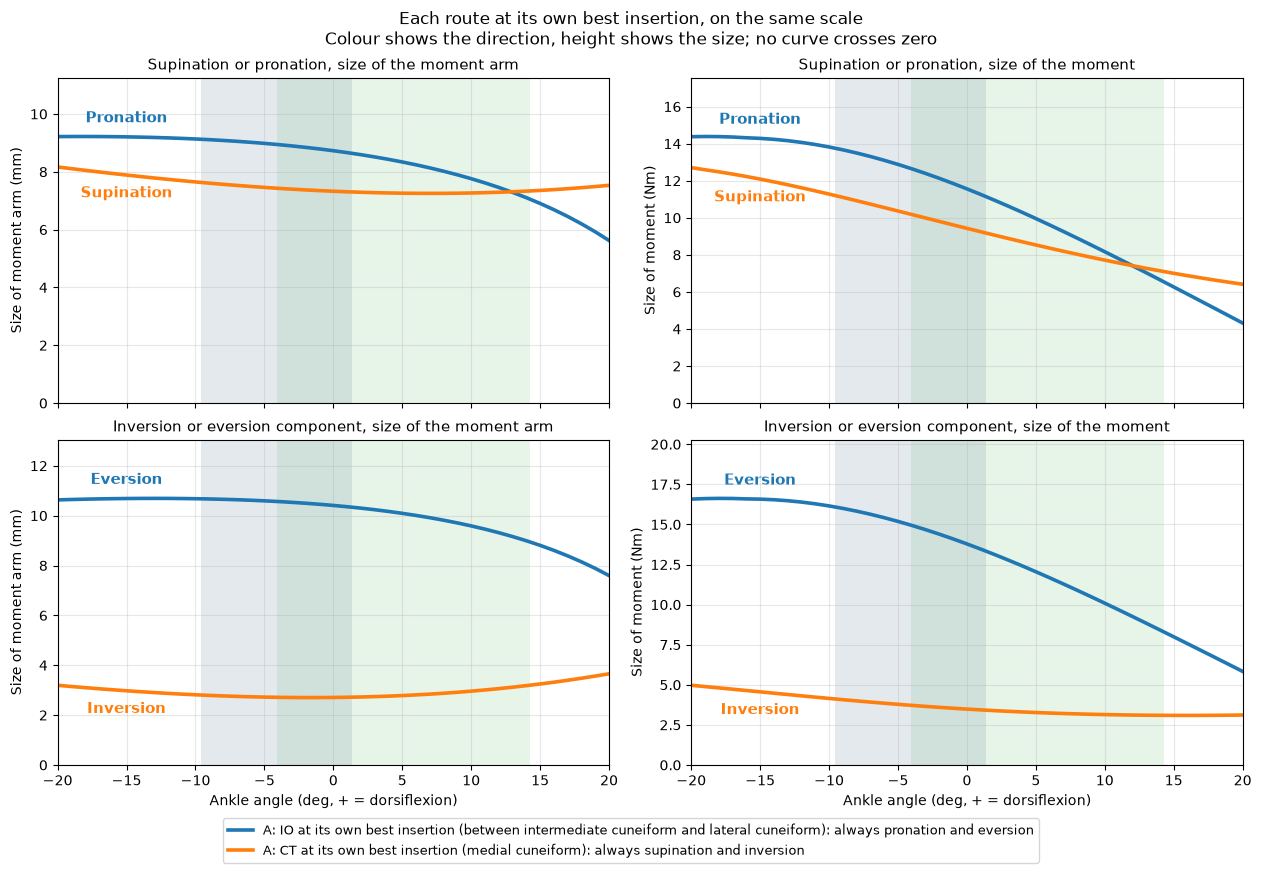

In [ ]:
DIRECTION = {  # 每個組合在兩排各是什麼方向
    'A_IO': ('pronation', 'eversion'), 'B_IO': ('pronation', 'eversion'),
    'A_CT': ('supination', 'inversion'),
}
rows_spec = [('supination_arm_mm', 'supination_moment_Nm', 'Supination or pronation'),
             ('inversion_arm_mm', 'inversion_moment_Nm', 'Inversion or eversion component')]
MAIN = ['A_IO', 'A_CT']  # 只畫 A 組合，B 是對照，不放進這張圖
LABEL_X = -15  # 方向字寫在這個角度的線旁邊
fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.6), constrained_layout=True, sharex=True)
for r, (arm_key, moment_key, title) in enumerate(rows_spec):
    for c, (key, unit) in enumerate(((arm_key, 'moment arm (mm)'), (moment_key, 'moment (Nm)'))):
        axis = axes[r][c]
        shade_gait(axis)
        sizes = {name: np.abs(curves[name][key]) for name in MAIN}
        at = ANGLES.index(LABEL_X)
        for name in MAIN:
            colour, width, line = STYLE[name]
            axis.plot(ANGLES, sizes[name], line, color=colour, linewidth=width,
                      label=f"{LABELS[name].split(', also used in B')[0]}: always {DIRECTION[name][0]} and {DIRECTION[name][1]}")
        top = max(size.max() for size in sizes.values())
        axis.set_ylim(0, top * 1.22)  # 從零開始，上面留空間給字，字才不會跑出框
        for name in MAIN:  # ⭐ 直接在線旁寫方向，比較高的那條寫在線上方，比較低的寫在線下方
            other = [n for n in MAIN if n != name][0]
            above = sizes[name][at] >= sizes[other][at]
            axis.annotate(DIRECTION[name][r].capitalize(), (LABEL_X, sizes[name][at]),
                          xytext=(0, 8 if above else -8), textcoords='offset points',
                          ha='center', va='bottom' if above else 'top', fontsize=10.5,
                          fontweight='bold', color=STYLE[name][0], annotation_clip=True)
        axis.set_title(f'{title}, size of the {unit.split(" (")[0]}', fontsize=10.5)
        axis.set_ylabel(f'Size of {unit}')
        axis.grid(alpha=0.3)
for axis in axes[1]:
    axis.set_xlabel('Ankle angle (deg, + = dorsiflexion)')
axes[0][0].set_xlim(-20, 20)
handles, labels = axes[0][0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=1, fontsize=9)  # 圖例放下面
fig.suptitle('Each route at its own best insertion, on the same scale\n'
             'Colour shows the direction, height shows the size; no curve crosses zero')
plt.savefig(os.path.join(FIGURES, 'v2-p2-magnitude-same-scale.png'), dpi=200, bbox_inches='tight')
plt.show()

### 👀 7.2. 怎麼讀圖三

1. 只有兩條線，**藍色 IO**、**橘色 CT**，兩條都接在自己最好的止點
2. 每條線旁邊直接寫了方向，上排 **Pronation／Supination**、下排 **Eversion／Inversion**
3. **上排右（力矩）** 兩條都從左往右往下，越背屈越小，在 +12° 左右交叉，之後 CT 的旋後比 IO 的旋前還大
4. **上排左（力臂）** 橘色幾乎是平的，藍色到 +10° 之後才往下
5. **下排（內翻／外翻分量）** IO 的外翻比 CT 的內翻大三到四倍，CT 的內翻力臂只有約 3 mm

### 📖 7.3. 為什麼力矩變小，力臂卻不一定：力矩 ＝ 肌腱力 × 力臂

1. Karan 的意思是，越背屈，轉位對後足的作用越小，因為肌肉快縮到底了
2. 力矩（moment）由兩個東西相乘
    - **力臂（moment arm）**　肌腱離關節軸多遠，純幾何，就是槓桿有多長
    - **肌腱力（tendon force）**　肌肉全力收縮能拉多大力，會隨肌肉長度變
3. 越背屈，轉位肌越短，離最佳長度越遠，能出的力越小，這就是 "run out of movement"
4. 這一格把三樣東西都除以**中立位 0° 的值**，所以三條線一定在 0° 交在 1，1 代表和中立位一樣，0.5 代表剩一半
    - ✏️ 2026-09-18 原本除以 −10° 的值，三條線交在 −10°，Karan 問為什麼不是 0°，所以改成中立位
5. 看 +14° 那一點　力臂的倍數 × 力的倍數 ＝ 力矩的倍數
6. 一樣只畫 A 組合，B 組合的數字印在下面，−10° 為基準的數字也一起印，和舊版對得起來

A_IO: at +14 deg relative to neutral, arm x0.81, force x0.71, moment x0.58
A_CT: at +14 deg relative to neutral, arm x1.00, force x0.76, moment x0.76
A_IO: at +14 deg relative to -10 deg, arm x0.78, force x0.62, moment x0.48
A_CT: at +14 deg relative to -10 deg, arm x0.96, force x0.66, moment x0.63
B_IO (not drawn): at +14 deg relative to -10 deg, arm x1.57, force x0.64, moment x1.01


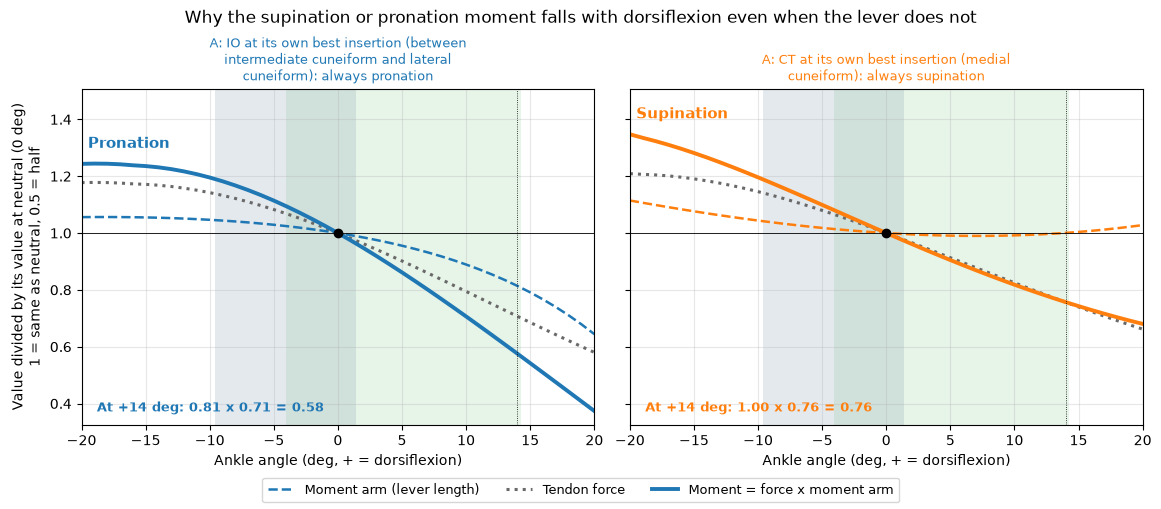

In [ ]:
REF = 0  # 中立位當基準，三條線都除以它在 0° 的值
ref, at14 = ANGLES.index(REF), ANGLES.index(14)
WORD = {'A_IO': 'Pronation', 'A_CT': 'Supination'}  # 力矩線旁邊寫的方向
fig, axes = plt.subplots(1, len(MAIN), figsize=(11.5, 5.0), sharey=True, constrained_layout=True)
for axis, name in zip(axes, MAIN):  # 只畫 A 組合
    colour = STYLE[name][0]
    arm = np.abs(curves[name]['supination_arm_mm'])  # 旋後或旋前力臂的大小
    force = curves[name]['force_N']  # 肌腱力
    moment = np.abs(curves[name]['supination_moment_Nm'])  # 力矩的大小
    shade_gait(axis)
    axis.plot(ANGLES, arm / arm[ref], '--', color=colour, linewidth=1.8, label='Moment arm (lever length)')
    axis.plot(ANGLES, force / force[ref], ':', color='dimgrey', linewidth=2.2, label='Tendon force')
    axis.plot(ANGLES, moment / moment[ref], '-', color=colour, linewidth=2.8, label='Moment = force x moment arm')
    axis.axhline(1, color='black', linewidth=0.6)
    axis.axvline(14, color='black', linewidth=0.6, linestyle=':')
    axis.plot(0, 1, 'o', color='black', markersize=6, zorder=5)  # 三條線在中立位都是 1
    # ⭐ 力矩線旁邊直接寫方向，從最左端往右寫，字在線的上方，才不會壓到往右下斜的線
    axis.annotate(WORD[name], (-19.5, moment[0] / moment[ref]), xytext=(0, 9),
                  textcoords='offset points', ha='left', va='bottom', fontsize=10.5,
                  fontweight='bold', color=colour, annotation_clip=True)
    factors = (arm[at14] / arm[ref], force[at14] / force[ref], moment[at14] / moment[ref])
    axis.text(0.03, 0.04, f'At +14 deg: {factors[0]:.2f} x {factors[1]:.2f} = {factors[2]:.2f}',
              transform=axis.transAxes, fontsize=9.5, fontweight='bold', color=colour)
    title = LABELS[name].split(', also used in B')[0]
    axis.set_title(textwrap.fill(f'{title}: always {WORD[name].lower()}', 42), fontsize=9, color=colour)
    axis.set_xlabel('Ankle angle (deg, + = dorsiflexion)')
    axis.set_xlim(-20, 20)
    axis.grid(alpha=0.3)
    print(f'{name}: at +14 deg relative to neutral, arm x{factors[0]:.2f}, '
          f'force x{factors[1]:.2f}, moment x{factors[2]:.2f}')
old = ANGLES.index(-10)  # 舊版的基準，印出來對帳
for name in shown:
    arm = np.abs(curves[name]['supination_arm_mm'])
    force = curves[name]['force_N']
    moment = np.abs(curves[name]['supination_moment_Nm'])
    drawn = '' if name in MAIN else ' (not drawn)'
    print(f'{name}{drawn}: at +14 deg relative to -10 deg, arm x{arm[at14] / arm[old]:.2f}, '
          f'force x{force[at14] / force[old]:.2f}, moment x{moment[at14] / moment[old]:.2f}')
axes[0].set_ylabel('Value divided by its value at neutral (0 deg)\n1 = same as neutral, 0.5 = half')
top = max(axis.get_ylim()[1] for axis in axes)
for axis in axes:
    axis.set_ylim(top=top * 1.08)  # 上面留一點空間給字
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=3, fontsize=9.5)
fig.suptitle('Why the supination or pronation moment falls with dorsiflexion even when the lever does not')
plt.savefig(os.path.join(FIGURES, 'v2-p2-moment-equals-force-times-arm.png'), dpi=200, bbox_inches='tight')
plt.show()

### 👀 7.3. 力矩 ＝ 肌腱力 × 力臂，拆開看

⭐ 三條線都除以自己在**中立位**的值，所以一定在 0° 交在 1，那個交點是除法造成的，不是生理現象。

| 從 0° 到 +14° | 力臂 | × 肌腱力 | ＝ 力矩 |
|---|---|---|---|
| IO，接自己的最佳點，旋前 | × 0.81 | × 0.71 | ＝ **0.58** |
| CT，接自己的最佳點，旋後 | × 1.00 | × 0.76 | ＝ **0.76** |

1. ⭐ **肌腱力兩條都掉到約四分之三**，越背屈肌肉越短，能出的力越小，這就是 Karan 說的 "run out of movement"
2. ⭐ **力臂不一樣**，IO 變短兩成，CT 完全不變
3. 所以**力矩一定被肌力拖下來，力臂決定拖多少**，IO 兩個都變小，掉最多
4. 用舊的基準 −10° 算，IO 0.78 × 0.62 ＝ 0.48、CT 0.96 × 0.66 ＝ 0.63，印在上面，結論一樣

---

## 8. 距下力矩拆成三個分量，隨踝角度變

### 📖 8.1. 為什麼可以拆，拆的時候要注意什麼

1. 距下關節只有一個斜的軸，轉位肌對它的力矩 **M**（Nm，正值旋後）是一個大小
2. 把 M 乘上軸的方向（單位向量），就得到一個三維的力矩向量，它在三個解剖軸上的投影就是三個分量
    - 前後軸（x）　**內翻（inversion）／外翻（eversion）**，冠狀面
    - 垂直軸（y）　**內收（adduction）／外展（abduction）**，橫切面
    - 內外軸（z）　**背屈（dorsiflexion）／蹠屈（plantarflexion）**，矢狀面
3. ⚠️ **距下軸掛在距骨上，踝背屈時距骨會轉，軸也跟著轉**
    - 所以要在每個踝角度重新讀軸的方向，用引擎的 `joint_axes()`
    - 再換到**小腿（脛骨）座標**，也就是臨床看後足的參考
4. ⚠️ §5 和 §7 的內翻分量用的是 `decompose()`，軸固定在中立位的方向，等於跟著腳轉的座標，這一格改成跟著小腿的座標
5. 方向約定和引擎一樣　內翻 ＝ −x 分量、內收 ＝ −y 分量、背屈 ＝ +z 分量

In [ ]:
def subtalar_axis_in_tibia():
    """目前姿勢下，距下軸（正向 ＝ 旋後）在脛骨座標裡的單位向量。"""
    engine.model.realizePosition(engine.state)
    direction = np.array(engine.joint_axes()['subtalar']['direction'])  # 地面座標
    tibia = engine.model.getBodySet().get('tibia_l').getTransformInGround(engine.state).R()
    rotation = np.array([[tibia.get(i, j) for j in range(3)] for i in range(3)])
    local = rotation.T @ direction  # 地面換到脛骨座標
    return local / np.linalg.norm(local)


components = {}
for name in tqdm(MAIN, desc='subtalar components'):
    route, position = CONFIGS[name]
    xyz, _ = xyz_at(route, position)
    engine.set_route(ROUTES[route], VIA_Y, insertion=xyz)
    shares, vectors = [], []
    for i, angle in enumerate(ANGLES):
        engine._pose(float(angle), 0.0)  # 只擺姿勢，力矩用 §4.1 算好的
        axis = subtalar_axis_in_tibia()
        # 每轉 1° 旋後帶出幾度內翻、內收、背屈，就是軸在三個解剖軸上的投影（速率，不是佔幾成）
        share = np.array([-axis[0], -axis[1], axis[2]])  # 內翻、內收、背屈
        shares.append(share)
        vectors.append(curves[name]['supination_moment_Nm'][i] * share)
    components[name] = {'share': np.array(shares), 'moment_Nm': np.array(vectors)}

# 檢查一：中立位的軸應該接近 .osim 裡的 (0.787, 0.605, -0.121)
at0 = ANGLES.index(0)
print('degrees per 1 degree of supination at neutral (inversion, adduction, dorsiflexion):',
      np.round(components['A_IO']['share'][at0], 3))
# 檢查二：三個分量平方和開根號，要等於距下力矩本身的大小
for name in MAIN:
    total = np.linalg.norm(components[name]['moment_Nm'], axis=1)
    gap = np.abs(total - np.abs(curves[name]['supination_moment_Nm'])).max()
    print(f'{name}: largest gap between |components| and |subtalar moment| {gap:.2e} Nm')

# 軸隨踝角度轉了多少
share = components['A_IO']['share']
for angle in (-20, -10, 0, 14, 20):
    i = ANGLES.index(angle)
    print(f'{angle:+3d} deg  per degree  inversion {share[i][0]:+.3f}  adduction {share[i][1]:+.3f}  '
          f'dorsiflexion {share[i][2]:+.3f}')

# 兩條路徑的三個分量，Nm
for name in MAIN:
    print(f'\n{name} components (Nm): inversion / adduction / dorsiflexion')
    for angle in (-10, 0, 14):
        i = ANGLES.index(angle)
        values = components[name]['moment_Nm'][i]
        print(f'  {angle:+3d} deg  {values[0]:+6.2f}  {values[1]:+6.2f}  {values[2]:+6.2f}')

with open(os.path.join(ROOT, 'V2_part2_subtalar_components.csv'), 'w', newline='', encoding='utf-8') as handle:
    writer = csv.writer(handle)
    writer.writerow(['config', 'ankle_deg', 'subtalar_moment_Nm', 'inversion_per_degree', 'adduction_per_degree',
                     'dorsiflexion_per_degree', 'inversion_Nm', 'adduction_Nm', 'dorsiflexion_Nm'])
    for name in MAIN:
        for i, angle in enumerate(ANGLES):
            writer.writerow([name, angle, round(curves[name]['supination_moment_Nm'][i], 4)]
                            + [round(v, 4) for v in components[name]['share'][i]]
                            + [round(v, 4) for v in components[name]['moment_Nm'][i]])

degrees per 1 degree of supination at neutral (inversion, adduction, dorsiflexion): [ 0.787  0.605 -0.121]
A_IO: largest gap between |components| and |subtalar moment| 3.55e-15 Nm
A_CT: largest gap between |components| and |subtalar moment| 1.78e-15 Nm
-20 deg  per degree  inversion +0.937  adduction +0.312  dorsiflexion -0.157
-10 deg  per degree  inversion +0.875  adduction +0.465  dorsiflexion -0.136
 +0 deg  per degree  inversion +0.787  adduction +0.605  dorsiflexion -0.121
+14 deg  per degree  inversion +0.627  adduction +0.772  dorsiflexion -0.108
+20 deg  per degree  inversion +0.546  adduction +0.831  dorsiflexion -0.107

A_IO components (Nm): inversion / adduction / dorsiflexion
  -10 deg  -12.09   -6.42   +1.89
   +0 deg   -9.10   -6.99   +1.40
  +14 deg   -4.17   -5.13   +0.72

A_CT components (Nm): inversion / adduction / dorsiflexion
  -10 deg   +9.87   +5.24   -1.54
   +0 deg   +7.42   +5.70   -1.14
  +14 deg   +4.47   +5.51   -0.77


### 👀 8.1. 軸會轉，而且轉很多

1. ✅ **中立位每轉 1° 旋後帶出** 內翻 0.787°、內收 0.605°、背屈 −0.121°，和 QA〈Ankle and Subtalar joint〉那張圖一樣
2. ✅ **三個分量合起來的大小** 等於距下力矩本身，差 1e−15 Nm
3. ⭐⭐ **踝一背屈，距下軸就站起來**

| 踝角度 | 每 1° 旋後的內翻 | 內收 | 背屈 |
|---|---|---|---|
| −20° | 0.94 | 0.31 | −0.16 |
| −10° | 0.88 | 0.47 | −0.14 |
| 0° | 0.79 | 0.61 | −0.12 |
| +14° | 0.63 | 0.77 | −0.11 |
| +20° | 0.55 | 0.83 | −0.11 |

4. 所以**蹠屈時距下的動作大多是內翻／外翻，背屈時大多變成內收／外展**，大約 +8° 兩條交叉
5. **兩條路徑的三個分量，−10° → +14°**
    - IO　外翻 −12.09 → −4.17 Nm，**少 66%**，外展 −6.42 → −5.13 Nm，背屈 +1.89 → +0.72 Nm
    - CT　內翻 +9.87 → +4.47 Nm，**少 55%**，內收 +5.24 → +5.51 Nm 幾乎不變，蹠屈 −1.54 → −0.77 Nm

### 📖 8.2. 畫圖五：三個分量畫在同一張圖

1. **左圖**　距下關節每轉 1° 旋後，帶出幾度內翻、內收、背屈，隨踝角度變，兩條路徑一樣，因為這只看骨頭的軸 / ⚠️ 是速率不是佔幾成，三個加起來不等於 1
2. **中圖 IO、右圖 CT**　距下力矩拆成三個分量，Nm
    - 綠色　內翻（+）／外翻（−）
    - 橘色　內收（+）／外展（−）
    - 藍色　背屈（+）／蹠屈（−）
    - 黑色虛線　⭐ **距下力矩本身，也就是旋後（+）／旋前（−）**，三條彩色線是把它拆開的三塊
3. 顏色和 QA 那張「三個軸分量」的圖一樣

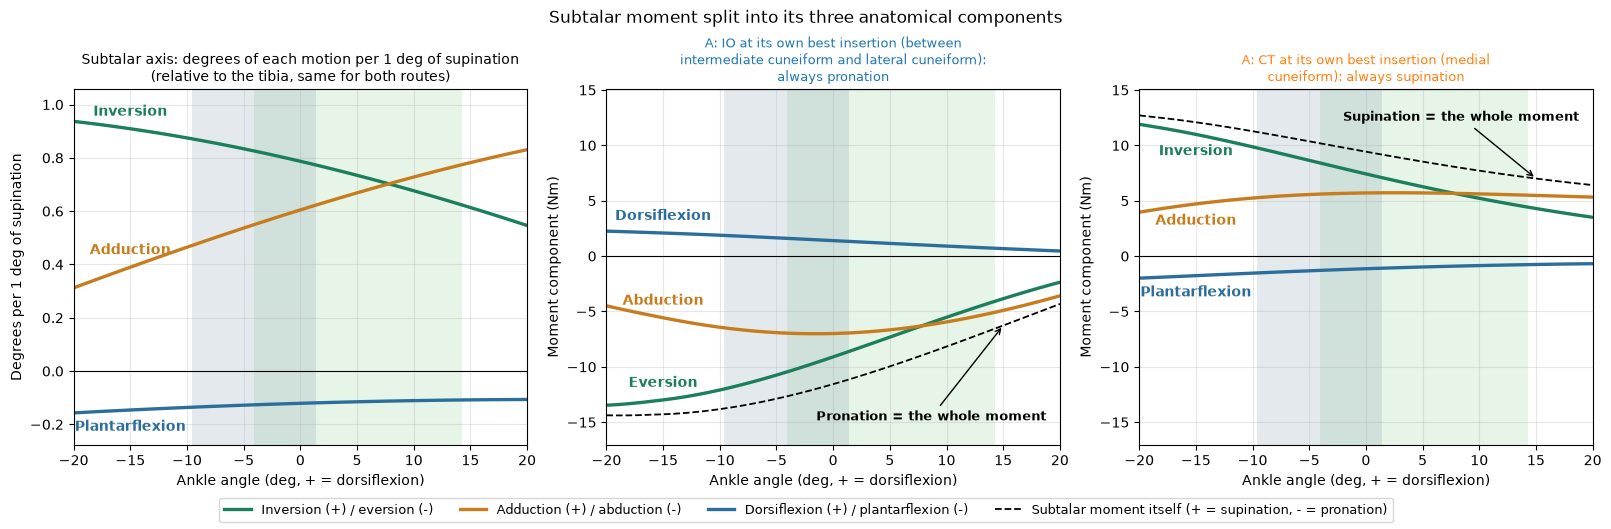

In [ ]:
COMPONENT_STYLE = [('Inversion (+) / eversion (-)', '#1b7f5b'),
                   ('Adduction (+) / abduction (-)', '#c77c1e'),
                   ('Dorsiflexion (+) / plantarflexion (-)', '#2c6e9b')]
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), constrained_layout=True)

# 左圖：軸的比例
axis = axes[0]
shade_gait(axis)
for k, (label, colour) in enumerate(COMPONENT_STYLE):
    axis.plot(ANGLES, components['A_IO']['share'][:, k], color=colour, linewidth=2.4, label=label)
axis.axhline(0, color='black', linewidth=0.8)
axis.set_title('Subtalar axis: degrees of each motion per 1 deg of supination\n(relative to the tibia, same for both routes)', fontsize=10)
axis.set_ylabel('Degrees per 1 deg of supination')

# 中圖、右圖：兩條路徑的三個分量
for axis, name in zip(axes[1:], MAIN):
    shade_gait(axis)
    for k, (label, colour) in enumerate(COMPONENT_STYLE):
        axis.plot(ANGLES, components[name]['moment_Nm'][:, k], color=colour, linewidth=2.4, label=label)
    axis.plot(ANGLES, curves[name]['supination_moment_Nm'], '--', color='black',
              linewidth=1.3, label='Subtalar moment itself (+ = supination, - = pronation)')
    # ⭐ 虛線就是旋後／旋前本身，直接寫在線旁邊；負的寫在線下方，正的寫在線上方
    # 字放在框內空白的角落，用箭頭指到虛線，才不會壓線或跑出框
    whole = curves[name]['supination_moment_Nm'][ANGLES.index(15)]
    corner = (0.97, 0.06) if whole < 0 else (0.97, 0.94)
    axis.annotate(('Pronation' if whole < 0 else 'Supination') + ' = the whole moment',
                  xy=(15, whole), xycoords='data', xytext=corner, textcoords='axes fraction',
                  ha='right', va='bottom' if whole < 0 else 'top', fontsize=9.5,
                  fontweight='bold', color='black',
                  arrowprops=dict(arrowstyle='->', color='black', linewidth=1))
    axis.axhline(0, color='black', linewidth=0.8)
    direction = 'pronation' if name == 'A_IO' else 'supination'
    axis.set_title(textwrap.fill(f"{LABELS[name].split(', also used in B')[0]}: always {direction}", 46),
                   fontsize=9.5, color=STYLE[name][0])
    axis.set_ylabel('Moment component (Nm)')
lows = min(axes[1].get_ylim()[0], axes[2].get_ylim()[0])
highs = max(axes[1].get_ylim()[1], axes[2].get_ylim()[1])
for axis in axes[1:]:
    axis.set_ylim(lows * 1.12, highs * 1.12)  # 兩條路徑同一個刻度，上下留空間給字

# ⭐ 每條線旁邊直接寫方向，用那個角度的正負號決定寫哪一個字
WORDS = [('Inversion', 'Eversion'), ('Adduction', 'Abduction'), ('Dorsiflexion', 'Plantarflexion')]
LABEL_AT = ANGLES.index(-15)
panels = [(axes[0], components['A_IO']['share'], None)] + [
    (axes[1 + j], components[n]['moment_Nm'], curves[n]['supination_moment_Nm'][LABEL_AT])
    for j, n in enumerate(MAIN)]
for axis, values, dashed in panels:
    for k, (positive, negative) in enumerate(WORDS):
        value = values[LABEL_AT, k]
        # 字寫在離黑色虛線遠的那一邊，才不會壓到線；左圖沒有虛線，就看正負號
        above = value > 0 if dashed is None else value > dashed
        axis.annotate(positive if value > 0 else negative, (-15, value),
                      xytext=(0, 7 if above else -7), textcoords='offset points',
                      ha='center', va='bottom' if above else 'top', fontsize=10,
                      fontweight='bold', color=COMPONENT_STYLE[k][1], annotation_clip=True)
top = max(components['A_IO']['share'].max(), 0)
axes[0].set_ylim(components['A_IO']['share'].min() - 0.12, top + 0.12)  # 左圖也留空間
for axis in axes:
    axis.set_xlim(-20, 20)
    axis.set_xlabel('Ankle angle (deg, + = dorsiflexion)')
    axis.grid(alpha=0.3)
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=4, fontsize=9.5)
fig.suptitle('Subtalar moment split into its three anatomical components')
plt.savefig(os.path.join(FIGURES, 'v2-p2-subtalar-three-components.png'), dpi=200, bbox_inches='tight')
plt.show()

### 👀 8.2. 怎麼讀圖五

1. **左圖** 每轉 1° 旋後，綠色（內翻）越背屈越少、橘色（內收）越背屈越多，+8° 左右交叉，藍色（蹠屈）一直很小
2. **中圖 IO** 三條都在同一邊，外翻、外展、一點點背屈，合起來就是旋前
3. **右圖 CT** 內翻、內收、一點點蹠屈，合起來就是旋後
4. ⭐ **旋後／旋前本身就是黑色虛線**，圖上用箭頭標了 "the whole moment"，三條彩色線是把它拆開的三塊，三塊平方加起來開根號等於虛線的大小
5. ⭐ **綠色（內翻／外翻）兩條路徑都是越背屈越小**，掉得比黑色虛線（距下力矩本身）還快
    - 原因有兩個疊在一起，肌腱力變小（約 × 0.64），加上軸站起來、每 1° 帶出的內翻變少（0.88 → 0.63，× 0.72）
    - IO　0.48 × 0.72 ＝ 0.34，剩三分之一
6. ⭐ **橘色（內收／外展）幾乎不變**，因為力變小，剛好被每 1° 帶出的內收變多抵掉
7. ⚠️ §7 的內翻分量是整個轉位肌的力矩向量、軸固定在中立位，這裡是只看距下關節、軸跟著轉，所以數字不同，**趨勢一樣，這裡掉得更多**

---

## 9. 踝和距下兩個關節的力矩向量加起來

### 📖 9.1. 為什麼可以加，加起來代表什麼

1. 轉位肌同時跨過兩個關節
    - 繞**踝軸**的力矩，幾乎全部是背屈（dorsiflexion），每 1° 帶出 0.98° 背屈
    - 繞**距下軸**的力矩，是旋後（supination）或旋前（pronation）
2. 每一個力矩乘上自己的軸，就是一個三維向量，兩個向量**相加**，就是轉位肌想把整個腳相對小腿往哪個方向轉
    - 這就是 moment arm vector（MAV）的做法，Dostal 1986 用在髖關節，第一版的 `decompose()` 和網頁規劃器的 "Total" 箭頭也是這樣算
3. 相加之後再拆成三個解剖分量，每一個分量 ＝ 踝的那一塊 ＋ 距下的那一塊
    - 內翻（+）／外翻（−）、內收（+）／外展（−）、背屈（+）／蹠屈（−）
4. ⚠️ 兩個軸都在每個踝角度重讀，換到小腿（脛骨）座標，和 §8 一樣

In [ ]:
def axis_in_tibia(key):
    """目前姿勢下，某個關節軸在脛骨座標裡的單位向量。"""
    engine.model.realizePosition(engine.state)
    direction = np.array(engine.joint_axes()[key]['direction'])
    tibia = engine.model.getBodySet().get('tibia_l').getTransformInGround(engine.state).R()
    rotation = np.array([[tibia.get(i, j) for j in range(3)] for i in range(3)])
    local = rotation.T @ direction
    return local / np.linalg.norm(local)


def anatomical(vector):
    """力矩向量換成臨床方向：內翻 ＝ −x、內收 ＝ −y、背屈 ＝ +z。"""
    return np.array([-vector[0], -vector[1], vector[2]])


combined = {}
for name in tqdm(MAIN, desc='ankle + subtalar'):
    route, position = CONFIGS[name]
    xyz, _ = xyz_at(route, position)
    engine.set_route(ROUTES[route], VIA_Y, insertion=xyz)
    ankle_part, subtalar_part = [], []
    for i, angle in enumerate(ANGLES):
        engine._pose(float(angle), 0.0)
        ankle_moment = curves[name]['dorsi_arm_mm'][i] / 1000 * curves[name]['force_N'][i]  # 背屈力矩，Nm
        ankle_part.append(anatomical(ankle_moment * axis_in_tibia('ankle')))
        subtalar_part.append(anatomical(curves[name]['supination_moment_Nm'][i] * axis_in_tibia('subtalar')))
    ankle_part, subtalar_part = np.array(ankle_part), np.array(subtalar_part)
    combined[name] = {'ankle': ankle_part, 'subtalar': subtalar_part, 'total': ankle_part + subtalar_part}

# 檢查：中立位時兩個軸和 decompose() 用的一樣，所以總向量的三個分量除以肌腱力，要等於 §5.1 的力臂分量
at0 = ANGLES.index(0)
for name in MAIN:
    route, position = CONFIGS[name]
    xyz, _ = xyz_at(route, position)
    engine.set_route(ROUTES[route], VIA_Y, insertion=xyz)
    parts = engine.decompose(0.0)
    mine = combined[name]['total'][at0] / curves[name]['force_N'][at0] * 1000  # 換回 mm
    print(f"{name} at neutral: inversion {mine[0]:+.2f} mm (decompose {parts['inversion_mm']:+.2f}), "
          f"adduction {mine[1]:+.2f} mm (decompose {parts['adduction_mm']:+.2f})")

# 兩個軸夾幾度，說明為什麼總向量的大小不是兩塊平方相加
engine._pose(0.0, 0.0)
angle_between = np.degrees(np.arccos(np.dot(axis_in_tibia('ankle'), axis_in_tibia('subtalar'))))
print(f'ankle and subtalar axes are {angle_between:.0f} deg apart at neutral')

for name in MAIN:
    print(f'\n{name}: total moment components (Nm), inversion / adduction / dorsiflexion, and size')
    for angle in (-10, 0, 14):
        i = ANGLES.index(angle)
        total = combined[name]['total'][i]
        ankle_share = combined[name]['ankle'][i]
        print(f'  {angle:+3d} deg  total {total[0]:+6.2f} {total[1]:+6.2f} {total[2]:+6.2f}  '
              f'|total| {np.linalg.norm(total):5.1f}   ankle part {ankle_share[0]:+5.2f} {ankle_share[1]:+5.2f} {ankle_share[2]:+6.2f}')

with open(os.path.join(ROOT, 'V2_part2_ankle_plus_subtalar.csv'), 'w', newline='', encoding='utf-8') as handle:
    writer = csv.writer(handle)
    writer.writerow(['config', 'ankle_deg'] + [f'{part}_{axis}_Nm' for part in ('ankle', 'subtalar', 'total')
                                               for axis in ('inversion', 'adduction', 'dorsiflexion')])
    for name in MAIN:
        for i, angle in enumerate(ANGLES):
            row = [name, angle]
            for part in ('ankle', 'subtalar', 'total'):
                row += [round(v, 4) for v in combined[name][part][i]]
            writer.writerow(row)

A_IO at neutral: inversion -10.41 mm (decompose -10.41), adduction -11.14 mm (decompose -11.14)
A_CT at neutral: inversion +2.71 mm (decompose +2.71), adduction -0.64 mm (decompose -0.64)
ankle and subtalar axes are 108 deg apart at neutral

A_IO: total moment components (Nm), inversion / adduction / dorsiflexion, and size
  -10 deg  total -17.37 -15.17 +51.09  |total|  56.0   ankle part -5.28 -8.74 +49.20
   +0 deg  total -13.79 -14.76 +45.09  |total|  49.4   ankle part -4.69 -7.77 +43.69
  +14 deg  total  -7.35 -10.41 +30.40  |total|  33.0   ankle part -3.18 -5.27 +29.68

A_CT: total moment components (Nm), inversion / adduction / dorsiflexion, and size
  -10 deg  total  +5.14  -2.59 +42.54  |total|  42.9   ankle part -4.73 -7.83 +44.07
   +0 deg  total  +3.49  -0.82 +35.57  |total|  35.8   ankle part -3.94 -6.53 +36.71
  +14 deg  total  +1.95  +1.33 +22.73  |total|  22.9   ankle part -2.52 -4.18 +23.50


### 👀 9.1. 加起來之後

1. ✅ **對帳** 中立位的內翻、內收分量和 §5.1 的 `decompose()` 一模一樣（IO −10.41、−11.14 mm，CT +2.71、−0.64 mm）
2. 兩個軸在中立位夾 **108°**，不垂直，所以總向量的大小不是兩個力矩平方相加
3. ⭐ **踝的那一塊不只有背屈**，踝軸是斜的，每背屈 1° 帶出 0.10° 外翻（eversion）、0.17° 外展（abduction）
    - IO 中立位　踝的那一塊 外翻 −4.69、外展 −7.77、背屈 +43.69 Nm
4. 中立位總和（Nm）

| | 內翻（+）／外翻（−） | 內收（+）／外展（−） | 背屈（+） | 大小 |
|---|---|---|---|---|
| IO | −13.79 | −14.76 | +45.09 | 49.4 |
| CT | +3.49 | −0.82 | +35.57 | 35.8 |

### 📖 9.2. 畫圖六：三個分量，踝的一塊 ＋ 距下的一塊 ＝ 總和

1. 三排是三個分量，左欄 IO、右欄 CT
2. 點線是踝的那一塊，虛線是距下的那一塊，粗實線是兩塊加起來
3. 同一排用同一個刻度，兩條路徑可以直接比

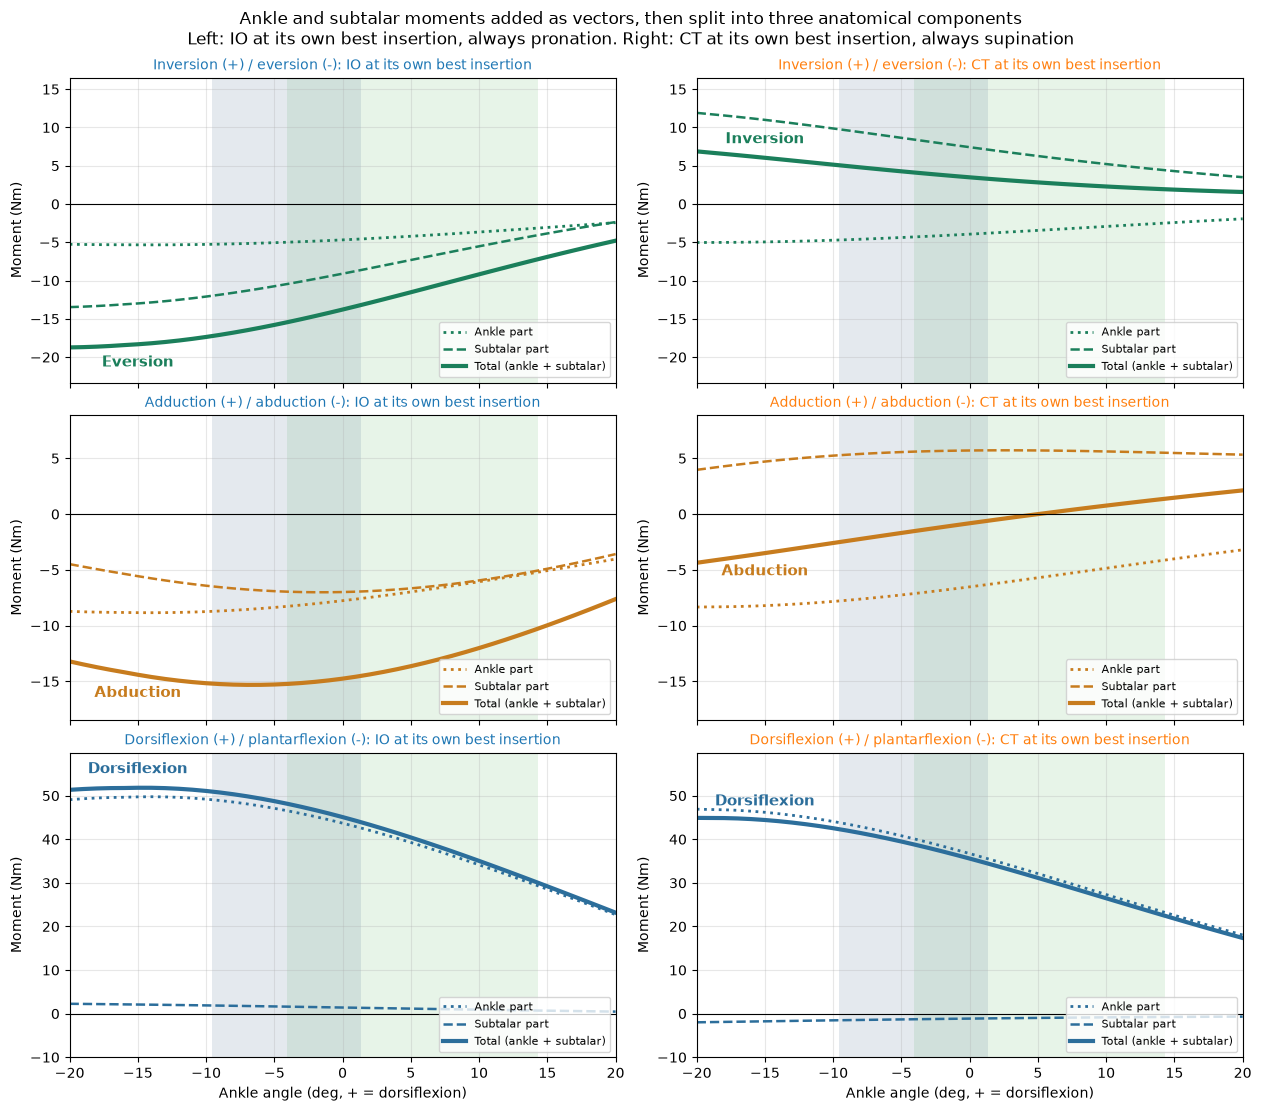

In [ ]:
COMPONENTS = [('Inversion (+) / eversion (-)', '#1b7f5b', ('Inversion', 'Eversion')),
              ('Adduction (+) / abduction (-)', '#c77c1e', ('Adduction', 'Abduction')),
              ('Dorsiflexion (+) / plantarflexion (-)', '#2c6e9b', ('Dorsiflexion', 'Plantarflexion'))]
fig, axes = plt.subplots(3, 2, figsize=(12.5, 11), sharex=True, constrained_layout=True)
for r, (title, colour, words) in enumerate(COMPONENTS):
    low = min(min(combined[n][p][:, r].min() for p in ('ankle', 'subtalar', 'total')) for n in MAIN)
    high = max(max(combined[n][p][:, r].max() for p in ('ankle', 'subtalar', 'total')) for n in MAIN)
    pad = (high - low) * 0.15
    for c, name in enumerate(MAIN):
        axis = axes[r][c]
        shade_gait(axis)
        axis.plot(ANGLES, combined[name]['ankle'][:, r], ':', color=colour, linewidth=2, label='Ankle part')
        axis.plot(ANGLES, combined[name]['subtalar'][:, r], '--', color=colour, linewidth=1.8, label='Subtalar part')
        total = combined[name]['total'][:, r]
        axis.plot(ANGLES, total, '-', color=colour, linewidth=3, label='Total (ankle + subtalar)')
        axis.axhline(0, color='black', linewidth=0.8)
        axis.set_ylim(min(low - pad, -pad), max(high + pad, pad))
        # 粗線旁邊寫方向，粗線在上半就寫上面，在下半就寫下面
        value = total[ANGLES.index(-15)]
        axis.annotate(words[0] if value > 0 else words[1], (-15, value), xytext=(0, 8 if value > 0 else -8),
                      textcoords='offset points', ha='center', va='bottom' if value > 0 else 'top',
                      fontsize=10.5, fontweight='bold', color=colour, annotation_clip=True)
        axis.set_title(f"{title}: {LABELS[name].split(' (')[0].replace('A: ', '')}", fontsize=10,
                       color=STYLE[name][0])
        axis.set_ylabel('Moment (Nm)')
        axis.grid(alpha=0.3)
        axis.legend(fontsize=8, loc='lower right')
for axis in axes[-1]:
    axis.set_xlabel('Ankle angle (deg, + = dorsiflexion)')
    axis.set_xlim(-20, 20)
fig.suptitle('Ankle and subtalar moments added as vectors, then split into three anatomical components\n'
             'Left: IO at its own best insertion, always pronation. Right: CT at its own best insertion, always supination')
plt.savefig(os.path.join(FIGURES, 'v2-p2-ankle-plus-subtalar-components.png'), dpi=200, bbox_inches='tight')
plt.show()

### 👀 9.2. 怎麼讀圖六

1. **最下排（背屈）** 粗線幾乎等於點線，總向量的背屈幾乎全部來自踝
2. ⭐ **IO（左欄）** 踝的那一塊和距下的那一塊**同方向**，外翻、外展加在一起變更大
3. ⭐⭐ **CT（右欄）** 兩塊**方向相反**
    - 距下推向內翻 +7.42、內收 +5.70 Nm，踝推向外翻 −3.94、外展 −6.53 Nm
    - 加起來內翻只剩 +3.49，內收變成 −0.82，大約 +6° 之後才又變回內收
4. ⛔ **這個抵消只存在於加總裡**，距下關節本身還是被推向旋後，踝的外翻分量推不到距下關節，因為兩個關節各自只能繞自己的軸轉
5. 所以**看畸形（距下旋後）要看距下自己（§8）**，總向量是「整個腳相對小腿想往哪轉」的描述